# Transportar suficientes estadísticas a C++20
## Pregunta y continuidad
Ayer fusionamos autoescalas en Python. Hoy un productor Python exporta un resumen hexadecimal; un ejecutable C++ lo consume y devuelve estado más SD. La utilidad es conectar componentes y reducir bytes sin trasladar filas. No hay nuevo estimador ni promesa de speedup.
# Transporte de resúmenes: qué se conserva y qué se pierde

## Original y brecha
El programa conserva Welford desplazado29, escala externa30, autoescala31 y fusión Chan entre escalas1nov. El resumen es (n,e,a,b,Q,i): n conteo, e exponente entero, a origen, b media relativa, Q suma centrada normalizada, i indica si hubo algún dato no nulo. Para y=x/2^e, μ_y=a+b y Q=Σ(y−μ_y)². Datos x tienen unidades U; y,a,b,Q son adimensionales. μ_x=2^e(a+b), V_d=2^{2e}Q/(n−d), SD_d=2^e sqrt(Q/(n−d)), d∈{0,1}, n>d. No hay un nuevo estimador.

La limitación del1nov era una API sólo en memoria Python. Hoy exportamos suficientes estadísticas numéricas a un consumidor C++20 real. No traducimos notebooks ni eliminamos fórmulas; el notebook enseña el contrato y llama al ejecutable.

## Identidad de serialización
Un binary64 finito representable es x=s·M·2^k con s∈{−1,1}, M entero de hasta53bits y k entero. `float.hex()` escribe esos bits como mantisa hexadecimal y exponente binario; cuatro bits por dígito hexadecimal evitan redondeo decimal de transporte. `float.fromhex` y `strtod` sobre la salida de exportación reconstruyen el mismo double bajo el toolchain probado. Se exige binary64 y redondeo habitual; no se demuestra equivalencia para toda implementación de C++.

El protocolo local es una línea ASCII con siete campos: `MOMENTS_V1 n e a_hex b_hex Q_hex initialized`. Exporta estado numérico, no contador histórico de reescalados o pérdidas. Al importar, esos diagnósticos se reinician a0; esto es explícito y evita confundir un resumen transportado con su trazabilidad completa. Datos originales, identidad de filas, autenticidad, firma y procedencia no están codificados.

## Derivación de la operación consumida
Para resúmenes disjuntos A,B, E es el mayor exponente entre resúmenes no nulos; un chunk de ceros no fija unidad. c_j=2^{e_j−E}; y'_j=c_jy_j. La media es lineal: a'_j=c_ja_j, b'_j=c_jb_j. Las diferencias centradas escalan por c_j, por lo que Q'_j=c_j²Q_j. Entonces:
$$a'_j=2^{e_j-E}a_j,\quad b'_j=2^{e_j-E}b_j,\quad Q'_j=2^{2(e_j-E)}Q_j.$$
$$\delta=(a'_B-a'_A)+(b'_B-b'_A),\quad n=n_A+n_B,$$
$$a=a'_A,\quad b=b'_A+\delta\frac{n_B}{n},\quad Q=Q'_A+Q'_B+\delta^2\frac{n_A n_B}{n}.$$
La última identidad sigue de separar Σ_A(y−μ)²=Q_A+n_A(μ_A−μ)² y B análogo: los términos cruzados son0 porque las desviaciones respecto de la media de cada grupo suman0. Sustituyendo μ_A−μ=−δn_B/n y μ_B−μ=δn_A/n se obtiene el término adicional. Es Chan conocido, no una fórmula científica nueva. `moments.hpp::merge` reproduce la operación después de parsear snapshots; `result_json` devuelve SD/varianza con los mismos estados de abstención que Python.

## Dominio y límites
Conteo 0≤n≤2^53−1; la suma de conteos no debe exceder ese máximo. Exponente −1073..1024, componentes finitos, |a|≤1, |b|≤2, 0≤Q≤4n. Estado vacío o sin dato no nulo exige exponent0 y componentes0. Son validaciones estructurales conservadoras, no prueba de que un estado provino de observaciones reales. El consumidor asume snapshots de productores válidos y particiones disjuntas; no identifica solapamiento ni valida causalidad/independencia.

En reales se conservan conteo, media y suma centrada. En máquina, serialización exacta no vuelve exacta la aritmética posterior ni recupera bits ya perdidos. Reescalar órdenes extremos puede redondear componentes a0; la pérdida histórica no viaja en este V1. Sólo se transportan estadísticas: no se pueden reconstruir observaciones ni recalcular otro estimando. Casos std_underflow/std_overflow devuelven SDnull; variance_underflow/overflow pueden conservar SD. El test[-minsubnormal,minsubnormal] conserva SDmin; [0,minsubnormal] puede abstenerse porque SDrealmin/2 no cabe. Exportar primero un decimal truncado es una ablación conceptualmente distinta y no se usa para fabricar superioridad.

## Utilidad y coste
Dos resúmenes ocupan un número constante de campos frente a n floats originales; bytes exactos y coste se miden. El proceso C++ se lanza por llamada: el coste de IPC domina, y no hay promesa de aceleración. El valor es conectar resúmenes y evitar reenvío de filas, no ganar a NumPy ni aportar un nuevo resultado estadístico. Ninguna garantía de privacidad diferencial: estadísticas también pueden revelar información.


In [1]:
import json,math,subprocess,shutil
from pathlib import Path
from IPython.display import display,Image
from src.transport import export_state,import_state
from src.cpp_bridge import consume
from src.benchmark_merge import summary,oracle
if not Path('.build/moments_consumer').exists():
    cmake=shutil.which('cmake')
    assert cmake, 'Install pinned requirements (including cmake) and a C++20 compiler; then bash run.sh'
    subprocess.run([cmake,'-S','.','-B','.build'],check=True,capture_output=True)
    subprocess.run([cmake,'--build','.build','-j2'],check=True,capture_output=True)
print(json.loads(Path('config_transport.json').read_text()))

{'seeds': [1102, 1103], 'sizes': [32, 1024], 'exponents': [-1070, 0, 1020], 'ddof': [0, 1], 'repeats': 5, 'dataset': 'synthetic clipped normal; received binary64 values', 'source': 'numpy default_rng', 'gate': 'Python/C++ SD discrepancy <= max(4ulp,1e-12 relative); roundtrip scalar state exact; payload reduction >10 at n1024', 'compiler': 'g++ C++20, -ffp-contract=off; default rounding assumed nearest', 'memory_scope': 'Python tracemalloc only; child C++ RSS not measured'}


## Producir, transportar y consumir
La línea contiene origen, media relativa y suma centrada en su unidad normalizada, no observaciones. Mostramos el snapshot exacto y la salida del consumidor, con comparación contra el oráculo.

In [2]:
a=summary([1.,2.,3.]);b=summary([1e200,2e200,3e200])
wire=export_state(a)
print('Snapshot:',wire)
assert import_state(wire).state==a.state
merged,out=consume(a,b,0)
print('Estado C++ devuelto:',export_state(merged));print('Resultado C++:',out)
expected=oracle([1.,2.,3.,1e200,2e200,3e200],0)
assert merged.state.n==6 and math.isclose(out['std'],expected,rel_tol=1e-12)

Snapshot: MOMENTS_V1 3 2 0x1.0000000000000p-2 0x1.0000000000000p-2 0x1.0000000000000p-3 1
Estado C++ devuelto: MOMENTS_V1 6 666 0x1.0000000000000p-666 0x1.4e718d7d7625ap-2 0x1.b4ec7f91973ffp-1 1
Resultado C++: {'status': 'variance_overflow', 'std': 1.1547005383792515e+200, 'variance': None}


## Casos límite y validación estructural
El parser rechaza versiones desconocidas y Q negativo. No certifica que un snapshot válido provenga de una muestra real. La SD puede caber cuando su cuadrado no cabe; también hay abstención subnormal.

In [3]:
tiny=math.ulp(0.)
for xs in [[-tiny,tiny],[0.,tiny],[-1.79e308,1.79e308]]:
    _,out=consume(summary(xs[:1]),summary(xs[1:]),0)
    print(xs,out)
assert consume(summary([-tiny]),summary([tiny]),0)[1]['std']==tiny
assert consume(summary([0.]),summary([tiny]),0)[1]['status']=='std_underflow'
try:
    import_state('MOMENTS_V1 2 0 0x0p+0 0x0p+0 -0x1p+0 1')
except ValueError:
    print('Q negativo rechazado explícitamente')
else:
    raise AssertionError('invalid snapshot accepted')

[-5e-324, 5e-324] {'status': 'variance_underflow', 'std': 5e-324, 'variance': 0}
[0.0, 5e-324] {'status': 'std_underflow', 'std': None, 'variance': None}
[-1.79e+308, 1.79e+308] {'status': 'variance_overflow', 'std': 1.79e+308, 'variance': None}
Q negativo rechazado explícitamente


## Experimento y contraste
24 escenarios (dos semillas, dos tamaños, tres escalas, dos ddof), tres métodos, cinco repeticiones. Python mide fusión de estados ya construidos; C++IPC incluye exportación, lanzamiento, parseo, operación y retorno. NumPy incluye recorrido offline de datos. Los costes no son kernels equivalentes: se reporta cada alcance y no se afirma aceleración. Hipótesis previas: discrepancia≤max(4ulp,1e−12relativo), roundtrip exacto de campos numéricos, reducción de bytes>10 en n1024.

In [4]:
results=json.loads(Path('results/transport_summary.json').read_text())
print(json.dumps(results,indent=2))
assert results['gate'] and results['minimum_payload_reduction_n1024']>10
print('Primeras3filas:',Path('results/transport_raw.csv').read_text().splitlines()[:4])

{
  "scenarios": 24,
  "rows": 72,
  "gate": true,
  "max_cpp_relative_sd_error": 4.545312815251244e-16,
  "max_python_cpp_discrepancy": 0.0,
  "minimum_payload_reduction_n1024": 132.55421686746988,
  "python": "3.12.14",
  "numpy": "2.3.5",
  "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
  "hardware": "x86_64",
  "compiler": "g++ (Ubuntu 13.3.0-6ubuntu2~24.04) 13.3.0",
  "cmake": "cmake version 4.1.2",
  "cost_scope": "python_merge excludes precomputed summaries; cpp_ipc includes export, process startup, parse/merge/output/import; NumPy includes input scan but is offline. No speedup claim. Imports/install excluded; memory Python heap only, child RSS unmeasured",
  "median_ns": {
    "python_merge": 6905.5,
    "cpp_ipc": 1743063.0,
    "numpy_scaled": 55693.5
  }
}
Primeras3filas: ['seed,n,exponent,ddof,method,sd,oracle_sd,relative_error,python_discrepancy,gate,median_ns,peak_python_bytes,summary_payload_bytes,raw_hex_payload_bytes,payload_reduction', '1102,32,-1070,0,python_merg

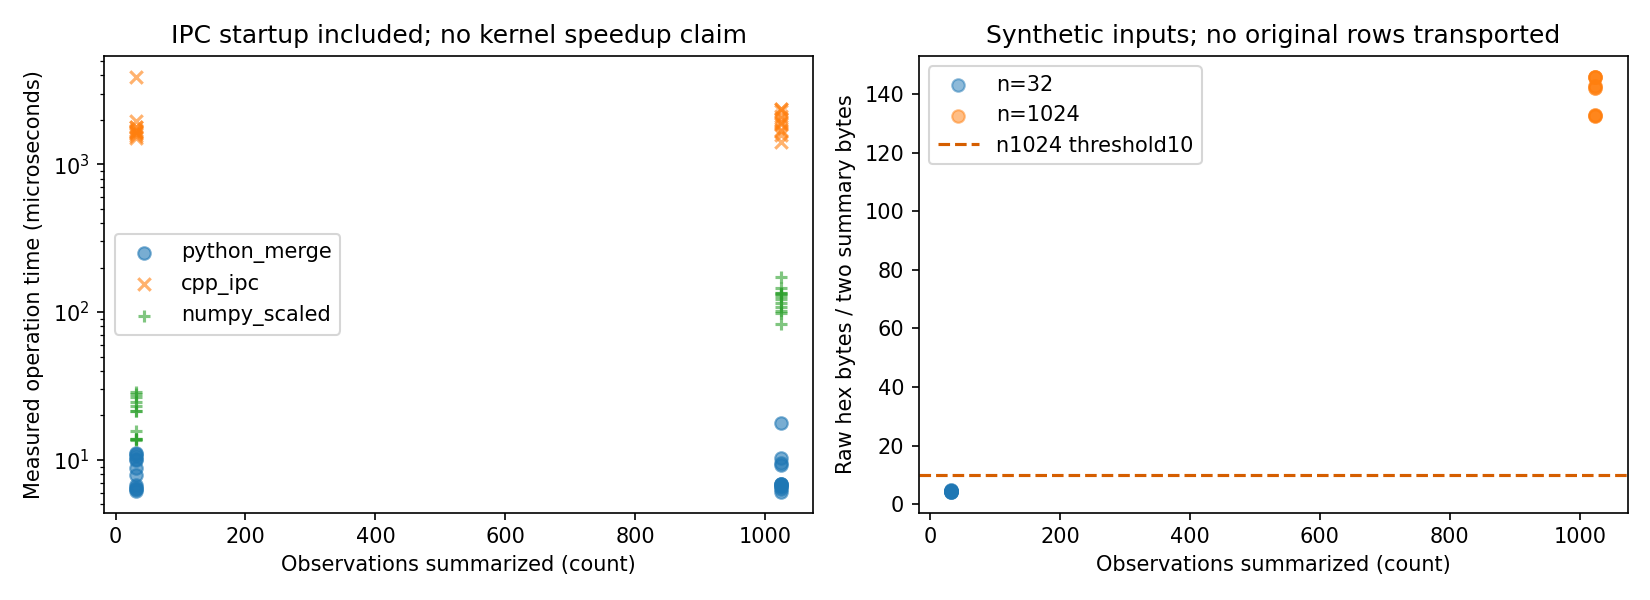

In [5]:
display(Image(filename='results/transport_audit.png'))

## Negativo que no debe ocultarse
El proceso nuevo por llamada es más lento. No se midió memoria del hijo C++; tracemalloc sólo cubre Python. V1 no transporta diagnósticos históricos: un contador cero al recibir no prueba ausencia de pérdidas anteriores.

In [6]:
state=summary([1e-300,2e-300,1e300])
print('Pérdidas detectadas antes de exportar:',state.rounded_to_zero)
received=import_state(export_state(state))
assert received.state==state.state and received.rounded_to_zero==0
print('Tras importar:',received.rounded_to_zero,'(historia omitida, no ausencia de pérdida)')
print('Costes ns:',results['median_ns'])
print('Ahora un consumidor C++ combina resúmenes Python sin recibir filas originales.')

Pérdidas detectadas antes de exportar: 3
Tras importar: 0 (historia omitida, no ausencia de pérdida)
Costes ns: {'python_merge': 6905.5, 'cpp_ipc': 1743063.0, 'numpy_scaled': 55693.5}
Ahora un consumidor C++ combina resúmenes Python sin recibir filas originales.


## Conclusión y siguiente hito
Adaptación de ingeniería verificada en casos sintéticos, no innovación científica ni validación operacional. Continuar contrato versionado; ajustar si se requieren diagnósticos/procedencia; cerrar promesa de velocidad por IPC. Próxima comparación: lote de resúmenes en un proceso persistente, sólo si amortiza IPC bajo el mismo presupuesto. Fuentes y alcance: prior_art_transport.md; referencias.bib; informe_transport.md14p y rúbricas.